#⚽ Prediction FIFA World Cup 2026 | Cristian David Miranda Garces &nbsp;&nbsp;





##**1. Introduccion**

La **Copa Mundial de la FIFA 2026** será la primera edición con **48 selecciones**, lo que representa un nuevo desafío para el análisis y la predicción del torneo. Determinar qué equipo tiene mayores probabilidades de convertirse en campeón requiere evaluar múltiples factores, como el rendimiento reciente, el historial en la competición, el valor de mercado de la plantilla, la experiencia mundialista y otros indicadores de desempeño.

El objetivo de este proyecto es analizar los datos históricos de las Copas Mundiales disputadas entre **2002 y 2022**, junto con la información de las **48 selecciones clasificadas para 2026**, para identificar los factores que más influyen en el éxito de una selección. A partir de este análisis se desarrolla un modelo de puntuación compuesta que permite comparar objetivamente a los equipos y estimar cuáles llegan al torneo con el perfil competitivo más sólido.

Para alcanzar este objetivo, el análisis busca responder las siguientes preguntas de investigación:

##**2. Preguntas de investigacion**

* ### ¿Cómo están representados los continentes en la Copa Mundial de la FIFA y cuál ha sido su distribución entre 2002 y 2022?

* ###  ¿Cómo ha sido el rendimiento reciente de las selecciones clasificadas para la Copa Mundial de la FIFA 2026?

* ###  ¿Influye el valor de mercado de una plantilla en el rendimiento de una selección durante la Copa Mundial?

* ### ¿Existe una relación entre la posición en el Ranking FIFA y las posibilidades de ganar la Copa Mundial?

* ### ¿La experiencia en Copas Mundiales aumenta las probabilidades de obtener mejores resultados en el torneo?

* ### ¿Qué tan significativa es la ventaja de ser el país anfitrión en la Copa Mundial de la FIFA?

* ### ¿Existe un rango óptimo de edad promedio en las plantillas de las selecciones campeonas del mundo?

* ###  ¿Qué selección presenta el perfil más sólido para ganar la Copa Mundial de la FIFA 2026?

##**3. Dataset**

###**3.1. Variables:**

| Variable (Inglés / Español) | Descripción |
|----------------------------|-------------|
| version (año del torneo) | Año de la Copa del Mundo a la que pertenece el registro. |
| team (selección) | Nombre de la selección nacional participante. |
| continent (continente) | Continente al que pertenece la selección (Europa, América, Asia, etc.). |
| is_host (es anfitrión) | Indica si el país organizó el Mundial. Generalmente 1 = Sí, 0 = No. |
| goals_scored_last_4y (goles anotados en los últimos 4 años) | Total de goles marcados por la selección durante el ciclo previo al Mundial. |
| goals_received_last_4y (goles recibidos en los últimos 4 años) | Total de goles encajados por la selección en el período previo al torneo. |
| wins_last_4y (victorias en los últimos 4 años) | Número de partidos ganados durante los cuatro años anteriores al Mundial. |
| losses_last_4y (derrotas en los últimos 4 años) | Número de partidos perdidos durante los cuatro años previos al torneo. |
| draws_last_4y (empates en los últimos 4 años) | Cantidad de partidos empatados en el ciclo previo al Mundial. |
| world_cup_titles_before (títulos mundiales previos) | Número de Copas del Mundo ganadas antes de ese torneo. |
| squad_total_market_value_eur (valor total de la plantilla en euros) | Suma del valor de mercado estimado de todos los jugadores convocados. |
| fifa_rank_pre_tournament (ranking FIFA previo al torneo) | Posición de la selección en el ranking FIFA antes del Mundial. Menor valor = mejor posición. |
| fifa_points_pre_tournament (puntos FIFA previos al torneo) | Puntuación oficial FIFA acumulada antes del inicio del Mundial. |
| squad_avg_age (edad promedio de la plantilla) | Edad media de los jugadores convocados para el torneo. |
| world_cup_participations_before (participaciones previas en Mundiales) | Número de veces que la selección había jugado una Copa del Mundo antes de ese torneo. |
| groups_passed_before (veces que superó la fase de grupos) | Cantidad de Mundiales anteriores en los que avanzó más allá de la fase de grupos. |
| round16_before (apariciones previas en octavos de final) | Número de veces que alcanzó los octavos de final anteriormente. |
| quarterfinals_before (apariciones previas en cuartos de final) | Cantidad de veces que llegó a cuartos de final en Mundiales anteriores. |
| semifinals_before (apariciones previas en semifinales) | Número de veces que alcanzó las semifinales antes de ese torneo. |
| finals_before (apariciones previas en finales) | Número de veces que disputó una final mundialista previamente. |
| winner (campeón) | Variable objetivo. Indica si la selección ganó el Mundial (1 = Sí, 0 = No). |
| finalist (finalista) | Indica si la selección llegó a la final (1 = Sí, 0 = No). |
| semi_finalist (semifinalista) | Indica si la selección alcanzó las semifinales (1 = Sí, 0 = No). |
| quarter_finalist (cuartofinalista) | Indica si la selección llegó a los cuartos de final (1 = Sí, 0 = No). |

###**3.2. Clasificacion de las variables:**


<small>

##### **Variables de Identificación**
- version
- team
- continent
</small>
<br>

<small>

##### **Variables de Contexto**
- is_host
</small>
<br>

<small>

##### **Variables de Rendimiento Reciente**
- goals_scored_last_4y
- goals_received_last_4y
- wins_last_4y
- losses_last_4y
- draws_last_4y
</small>

<br>

<small>

##### **Variables de Experiencia Histórica**
- world_cup_titles_before
- world_cup_participations_before
- groups_passed_before
- round16_before
- quarterfinals_before
- semifinals_before
- finals_before
</small>

<br>

<small>

##### **Variables de Calidad Actual del Equipo**
- squad_total_market_value_eur
- fifa_rank_pre_tournament
- fifa_points_pre_tournament
- squad_avg_age
</small>

<br>

<small>

##### **Variables Objetivo (Targets)**
- winner
- finalist
- semi_finalist
- quarter_finalist
</small>

##**4. Libreruias y visual**

###**4.1. Librerias a utilizar**


In [152]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import warnings
warnings.filterwarnings('ignore')





print("✅ Libraries loaded successfully")


✅ Libraries loaded successfully


###**4.2. Configuracion visual garficos**

In [153]:
pio.renderers.default = 'iframe' #Define cómo se visualizarán los gráficos interactivos de Plotly dentro de Colab.

sns.set_theme(style="whitegrid")               #Aplica un tema visual de seaborn
plt.rcParams['figure.dpi'] = 120               #resolucion de la figuras
plt.rcParams['font.family'] = 'sans-serif'     #tipo de fuente figuras
plt.rcParams['axes.titlesize'] = 14            #tamaño del titulo
plt.rcParams['axes.labelsize'] = 11            #tamaño de los texto de ejes

order = ['Winner', 'Finalist', 'Semi_finalist', 'Quarter_finalist', 'Group Stage / R16']

colors = {

    'Winner': '#FFB703',                     # DORADO
    'Finalist': '#00B4D8',                   # AZUL
    'Semi_finalist':'#2DC653' ,              # VERDE
    'Quarter_finalist': '#9B5DE5',           # MORADO
    'Group Stage / R16':  '#E63946'          # ROJO

    }




###**4.3. Dataset loading** <br>
**Dataset:** https://www.kaggle.com/datasets/harrachimustapha/fifa-world-cup-team-dataset?resource=download

**Limitaciones:**

- Lesiones
- Decisiones tácticas
- Compatibilidad del equipo
- Rendimiento de los jugadores
- Dificultad del sorteo
- Clima, viajes, presión y eventos inesperados
- Tandas de penaltis
- Sucesos fortuitos durante el partido

In [154]:
test = pd.read_csv('test.csv') #dataset con las selecciones del Mundial 2026
train = pd.read_csv('train.csv') #dataset history Mundial 2002-2022

print(f" Train: {train.shape} | Test: {test.shape}")
print(f"Editions in train: {sorted(train['version'].unique())}")
print(f"Teams in 2026 test set: {len(test)}")



 Train: (192, 24) | Test: (48, 24)
Editions in train: [np.int64(2002), np.int64(2006), np.int64(2010), np.int64(2014), np.int64(2018), np.int64(2022)]
Teams in 2026 test set: 48


##**5. Analisis del Dataset train**

### **5.1. view dataset train**

In [155]:
train

,version,team,continent,is_host,goals_scored_last_4y,goals_received_last_4y,wins_last_4y,losses_last_4y,draws_last_4y,world_cup_titles_before,...,world_cup_participations_before,groups_passed_before,round16_before,quarterfinals_before,semifinals_before,finals_before,winner,finalist,semi_finalist,quarter_finalist
0,2006,Angola,Africa,0,61,49,19,13,14,0,...,0,0,0,0,0,0,0,0,0,0
1,2006,Argentina,South America,0,97,55,31,10,10,2,...,13,10,5,6,4,4,0,0,0,1
2,2006,Australia,Oceania,0,101,34,23,8,5,0,...,1,0,0,0,0,0,0,0,0,0
3,2006,Brazil,South America,0,117,47,30,9,17,5,...,17,15,7,11,9,6,0,0,0,1
4,2006,Costa Rica,North America,0,89,84,26,25,11,0,...,2,1,1,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,2002,Sweden,Europe,0,64,29,24,8,16,0,...,9,6,2,4,3,1,0,0,0,0
188,2002,Tunisia,Africa,0,85,44,23,11,16,0,...,2,0,0,0,0,0,0,0,0,0
189,2002,Turkey,Europe,0,46,33,15,10,11,0,...,1,0,0,0,0,0,0,0,1,1
190,2002,United States,North America,0,91,46,30,16,13,0,...,6,3,2,1,1,0,0,0,0,1


In [156]:
# Corregir nombre de Curacao
test['team'] = test['team'].replace('Cura?o', 'Curacao')



###**5.2. Exploracion de columnas**

In [157]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 192 entries, 0 to 191
Data columns (total 24 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   version                          192 non-null    int64  
 1   team                             192 non-null    object 
 2   continent                        192 non-null    object 
 3   is_host                          192 non-null    int64  
 4   goals_scored_last_4y             192 non-null    int64  
 5   goals_received_last_4y           192 non-null    int64  
 6   wins_last_4y                     192 non-null    int64  
 7   losses_last_4y                   192 non-null    int64  
 8   draws_last_4y                    192 non-null    int64  
 9   world_cup_titles_before          192 non-null    int64  
 10  squad_total_market_value_eur     160 non-null    float64
 11  fifa_rank_pre_tournament         192 non-null    int64  
 12  fifa_points_pre_tourna


###**5.3. Datos Faltantes**

In [158]:
# Datos faltantes por columna
print("\nDatos faltantes por columna:")
print(train.isnull().sum())


Datos faltantes por columna:
version                             0
team                                0
continent                           0
is_host                             0
goals_scored_last_4y                0
goals_received_last_4y              0
wins_last_4y                        0
losses_last_4y                      0
draws_last_4y                       0
world_cup_titles_before             0
squad_total_market_value_eur       32
fifa_rank_pre_tournament            0
fifa_points_pre_tournament          0
squad_avg_age                       0
world_cup_participations_before     0
groups_passed_before                0
round16_before                      0
quarterfinals_before                0
semifinals_before                   0
finals_before                       0
winner                              0
finalist                            0
semi_finalist                       0
quarter_finalist                    0
dtype: int64


#### **5.3.1. Tratamiento de valores faltantes en `squad_total_market_value_eur`**



#####La variable `squad_total_market_value_eur` presenta 32 valores faltantes, correspondientes exclusivamente a las selecciones participantes en la Copa Mundial de la FIFA 2002. Para imputar estos valores se utilizó información de la edición 2006, la más cercana disponible en el conjunto de datos.

### Identificación de grupos

Las selecciones de 2002 se dividieron en dos grupos:

<br>

* **Grupo 1:** selecciones que participaron tanto en 2002 como en 2006 (20 equipos).
* **Grupo 2:** selecciones que participaron en 2002 pero no clasificaron al Mundial 2006 (12 equipos).

<br>

### Grupo 1: Selecciones que repitieron en 2006

Para estas selecciones, el valor faltante de 2002 fue reemplazado por el valor registrado en 2006.

| Selección     | Valor de mercado 2006 (€) |
| ------------- | ------------------------: |
| England       |             1,620,000,000 |
| France        |             1,350,000,000 |
| Spain         |             1,310,000,000 |
| Portugal      |               864,500,000 |
| Brazil        |               858,500,000 |
| Italy         |               838,500,000 |
| Argentina     |               777,200,000 |
| Germany       |               776,500,000 |
| Ecuador       |               387,830,000 |
| Sweden        |               363,780,000 |
| United States |               350,700,000 |
| Croatia       |               282,300,000 |
| Japan         |               262,200,000 |
| Poland        |               214,500,000 |
| Mexico        |               165,800,000 |
| Paraguay      |               141,850,000 |
| South Korea   |               139,750,000 |
| Tunisia       |                50,600,000 |
| Saudi Arabia  |                30,350,000 |
| Costa Rica    |                18,400,000 |

<br>

### Grupo 2: Selecciones del 2002 sin participación en 2006

* Belgium
* Cameroon
* China PR
* Denmark
* Nigeria
* Republic of Ireland
* Russia
* Senegal
* Slovenia
* South Africa
* Turkey
* Uruguay

### Cálculo del valor de imputación

Para estimar el valor de mercado de las selecciones del Grupo 2, se seleccionaron las ocho selecciones con menor valor de mercado dentro del Grupo 1:

| Selección    | Valor de mercado 2006 (€) |
| ------------ | ------------------------: |
| Costa Rica   |                18,400,000 |
| Saudi Arabia |                30,350,000 |
| Tunisia      |                50,600,000 |
| South Korea  |               139,750,000 |
| Paraguay     |               141,850,000 |
| Mexico       |               165,800,000 |
| Poland       |               214,500,000 |
| Japan        |               262,200,000 |


<br>

La media de estos ocho valores fue utilizada como valor para las doce selecciones del Grupo 2:

<br>

$$
\text{Media}=
\frac{
18.4+30.35+50.6+139.75+141.85+165.8+214.5+262.2
}{8}
\approx 127.9
\text{ millones de euros}
$$



<br>

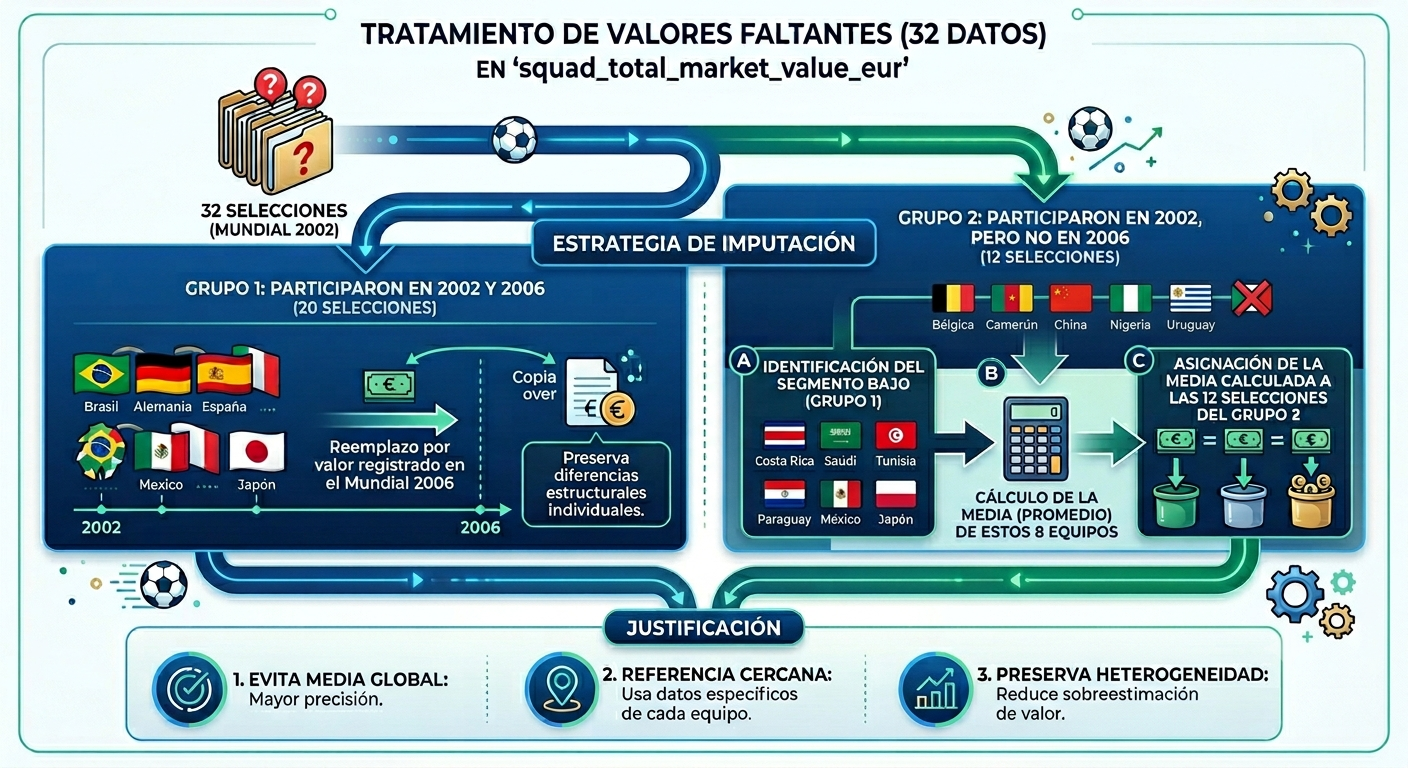

####**5.3.2. Justificacion del proceso de imputacion:**
Para las selecciones que no clasificaron al Mundial de 2006 se utilizó como referencia el promedio de las ocho selecciones con menor valor de mercado entre aquellas que sí participaron en dicha edición. La elección de este grupo responde a que representan el segmento competitivo más cercano disponible dentro del conjunto de datos, caracterizado por una menor presencia de jugadores en ligas de élite y una valoración económica más reducida de sus plantillas.

Adicionalmente, se observa que existe cierta correspondencia regional entre ambos grupos. Por ejemplo, selecciones asiáticas como China PR presentan características más comparables con Japón, Corea del Sur o Arabia Saudita que con potencias europeas; de manera similar, Senegal comparte un contexto competitivo más cercano a selecciones de valor medio-bajo que a equipos de élite como Francia o Inglaterra. Esto permite que la estimación conserve cierta coherencia tanto deportiva como geográfica.

En consecuencia, el promedio de las ocho selecciones de menor valor del Grupo 1 constituye una aproximación conservadora que reduce el riesgo de sobreestimar el valor de mercado de las selecciones ausentes en 2006.

In [159]:
# Equipos que participaron en 2002 y 2006
teams_2002 = set(train[train['version'] == 2002]['team'])
teams_2006 = set(train[train['version'] == 2006]['team'])

repeated_teams = teams_2002.intersection(teams_2006)
not_repeated_teams = teams_2002 - teams_2006

# Grupo 1: Copiar valor 2006 -> 2002

for team in repeated_teams:

    value_2006 = train.loc[
        (train['version'] == 2006) &
        (train['team'] == team),
        'squad_total_market_value_eur'
    ].iloc[0]

    train.loc[
        (train['version'] == 2002) &
        (train['team'] == team),
        'squad_total_market_value_eur'
    ] = value_2006

    # Verificamos

train[
    (train['version'] == 2002) &
    (train['team'].isin(repeated_teams))
][['team','squad_total_market_value_eur']].sort_values('team')

,team,squad_total_market_value_eur
160,Argentina,7.772000e+08
162,Brazil,8.585000e+08
165,Costa Rica,1.840000e+07
166,Croatia,2.823000e+08
168,Ecuador,3.878300e+08
169,England,1.620000e+09
170,France,1.350000e+09
171,Germany,7.765000e+08
172,Italy,8.385000e+08
173,Japan,2.622000e+08


In [160]:
# Grupo 2: Agregar el valor de la media de los 8 ultimos paises del grupo 1
train.loc[
    (train['version'] == 2002) &
    (train['squad_total_market_value_eur'].isna()),
    'squad_total_market_value_eur'
] = 127931250

# Verificamos

train[
    (train['version'] == 2002) &
    (train['team'].isin(not_repeated_teams))
][['team', 'squad_total_market_value_eur']]

,team,squad_total_market_value_eur
161,Belgium,127931250.0
163,Cameroon,127931250.0
164,China PR,127931250.0
167,Denmark,127931250.0
175,Nigeria,127931250.0
179,Republic of Ireland,127931250.0
180,Russia,127931250.0
182,Senegal,127931250.0
183,Slovenia,127931250.0
184,South Africa,127931250.0


In [161]:
display(
    train[['team', 'version', 'squad_total_market_value_eur']]
    .sort_values(['version', 'team'])
)

,team,version,squad_total_market_value_eur
160,Argentina,2002,777200000.0
161,Belgium,2002,127931250.0
162,Brazil,2002,858500000.0
163,Cameroon,2002,127931250.0
164,China PR,2002,127931250.0
...,...,...,...
91,Switzerland,2022,281000000.0
92,Tunisia,2022,62400000.0
93,United States,2022,277400000.0
94,Uruguay,2022,449700000.0


##**6. Feature Engineering**


<small>

"Se crearon nuevas variables derivadas con el objetivo de obtener métricas más representativas del rendimiento y facilitar la interpretación de los datos."

###**6.1. Nuevas colunnas**

In [162]:
for df in [train, test]:

  # Partidos jugados = Victorias + Derrotas + Empates
  df['games_played'] = df["wins_last_4y"] + df["draws_last_4y"] + df["losses_last_4y"]

  # Win Rate = Victorias / Partidos jugados
  df['win_rate'] = (df['wins_last_4y'] / df['games_played']).round(3)

  # Diferencia de goles = Goles anotados - Goles recibidos
  df['goal_diff'] = df['goals_scored_last_4y'] - df['goals_received_last_4y']

  df['market_value_M'] = (df['squad_total_market_value_eur'] / 1000000).round(1)



In [163]:
# Mostrar las nuevas variables creadas

train[['team',
       'games_played',
       'win_rate',
       'goal_diff',
       'market_value_M']]

,team,games_played,win_rate,goal_diff,market_value_M
0,Angola,46,0.413,12,52.7
1,Argentina,51,0.608,42,777.2
2,Australia,36,0.639,67,48.0
3,Brazil,56,0.536,70,858.5
4,Costa Rica,62,0.419,5,18.4
...,...,...,...,...,...
187,Sweden,48,0.500,35,363.8
188,Tunisia,50,0.460,41,50.6
189,Turkey,36,0.417,13,127.9
190,United States,59,0.508,45,350.7


###**6.2. Etiquetas de rendimiento de los paises** *texto en cursiva*

In [164]:
def get_performance(row):

  # Campeon
  if row['winner'] == 1:
    return 'Winner'

  # Finalista
  elif row['finalist'] ==1:
      return 'Finalist'

  # Semifinalista
  elif row['semi_finalist'] == 1:
        return 'Semi_finalist'

  # Cuartofinalista
  elif row['quarter_finalist'] == 1:
          return 'Quarter_finalist'

  else:
    return 'Group Stage / R16'

train['performance'] = train.apply(get_performance, axis=1)



In [165]:
print(f"\nQuick check — Winners: {train['winner'].sum()} | Finalists: {train['finalist'].sum()} | Semi: {train['semi_finalist'].sum()} | quarter_finalist: {train['quarter_finalist'].sum()}" )


Quick check — Winners: 6 | Finalists: 12 | Semi: 24 | quarter_finalist: 48


In [166]:
# Ver cómo quedó clasificada cada selección

train[['team', 'performance']]

,team,performance
0,Angola,Group Stage / R16
1,Argentina,Quarter_finalist
2,Australia,Group Stage / R16
3,Brazil,Quarter_finalist
4,Costa Rica,Group Stage / R16
...,...,...
187,Sweden,Group Stage / R16
188,Tunisia,Group Stage / R16
189,Turkey,Semi_finalist
190,United States,Quarter_finalist


In [167]:
train['performance'].value_counts()

,count
performance,
Group Stage / R16,144
Quarter_finalist,24
Semi_finalist,12
Finalist,6
Winner,6


##**7. Sistema de puntuacion en base a sus ultimas participaciones 2002/2022**

In [168]:


# Sistema de puntuación

points_map = {
    'Winner': 8,
    'Finalist': 6,
    'Semi_finalist': 4,
    'Quarter_finalist': 2,
    'Group Stage / R16': 0
}

# Asignar puntos a cada participación
train['wc_points'] = train['performance'].map(points_map)



In [169]:
country_ranking = (
    train.groupby('team')['wc_points']
         .sum()
         .sort_values(ascending=False)
         .reset_index()
)

country_ranking.head(24)

,team,wc_points
0,France,22
1,Germany,22
2,Brazil,20
3,Argentina,18
4,Netherlands,12
5,Croatia,10
6,Spain,10
7,England,10
8,Italy,8
9,Belgium,6


In [170]:
top10 = country_ranking.head(26)

fig = px.bar_polar(
    top10,
    r='wc_points',
    theta='team',
    color='wc_points',
    color_continuous_scale='Viridis',
    template='plotly_white'
)

fig.update_layout(
    title='World Cup Performance Score (2002–2022) TOP 10',
    polar=dict(
    radialaxis=dict(
        showticklabels=False,  # Oculta 5,10,15,20
        ticks=''               # Oculta las marcas
    )
)
)
fig.show(renderer="colab")

#**8. Solucion de preguntas de investigacion**
<small>

##**¿Cómo están representados los continentes en la Copa Mundial de la FIFA y cuál ha sido su distribución entre 2002 y 2022?**
<small>

> La Copa Mundial de la FIFA 2026 será una edición histórica al reunir por primera vez a **48 selecciones** y ser organizada conjuntamente por **Canadá, Estados Unidos y México**. La ampliación del torneo permite una mayor representación global, con equipos clasificados de las seis confederaciones de la FIFA, convirtiéndola en la Copa del Mundo más diversa y extensa hasta la fecha.

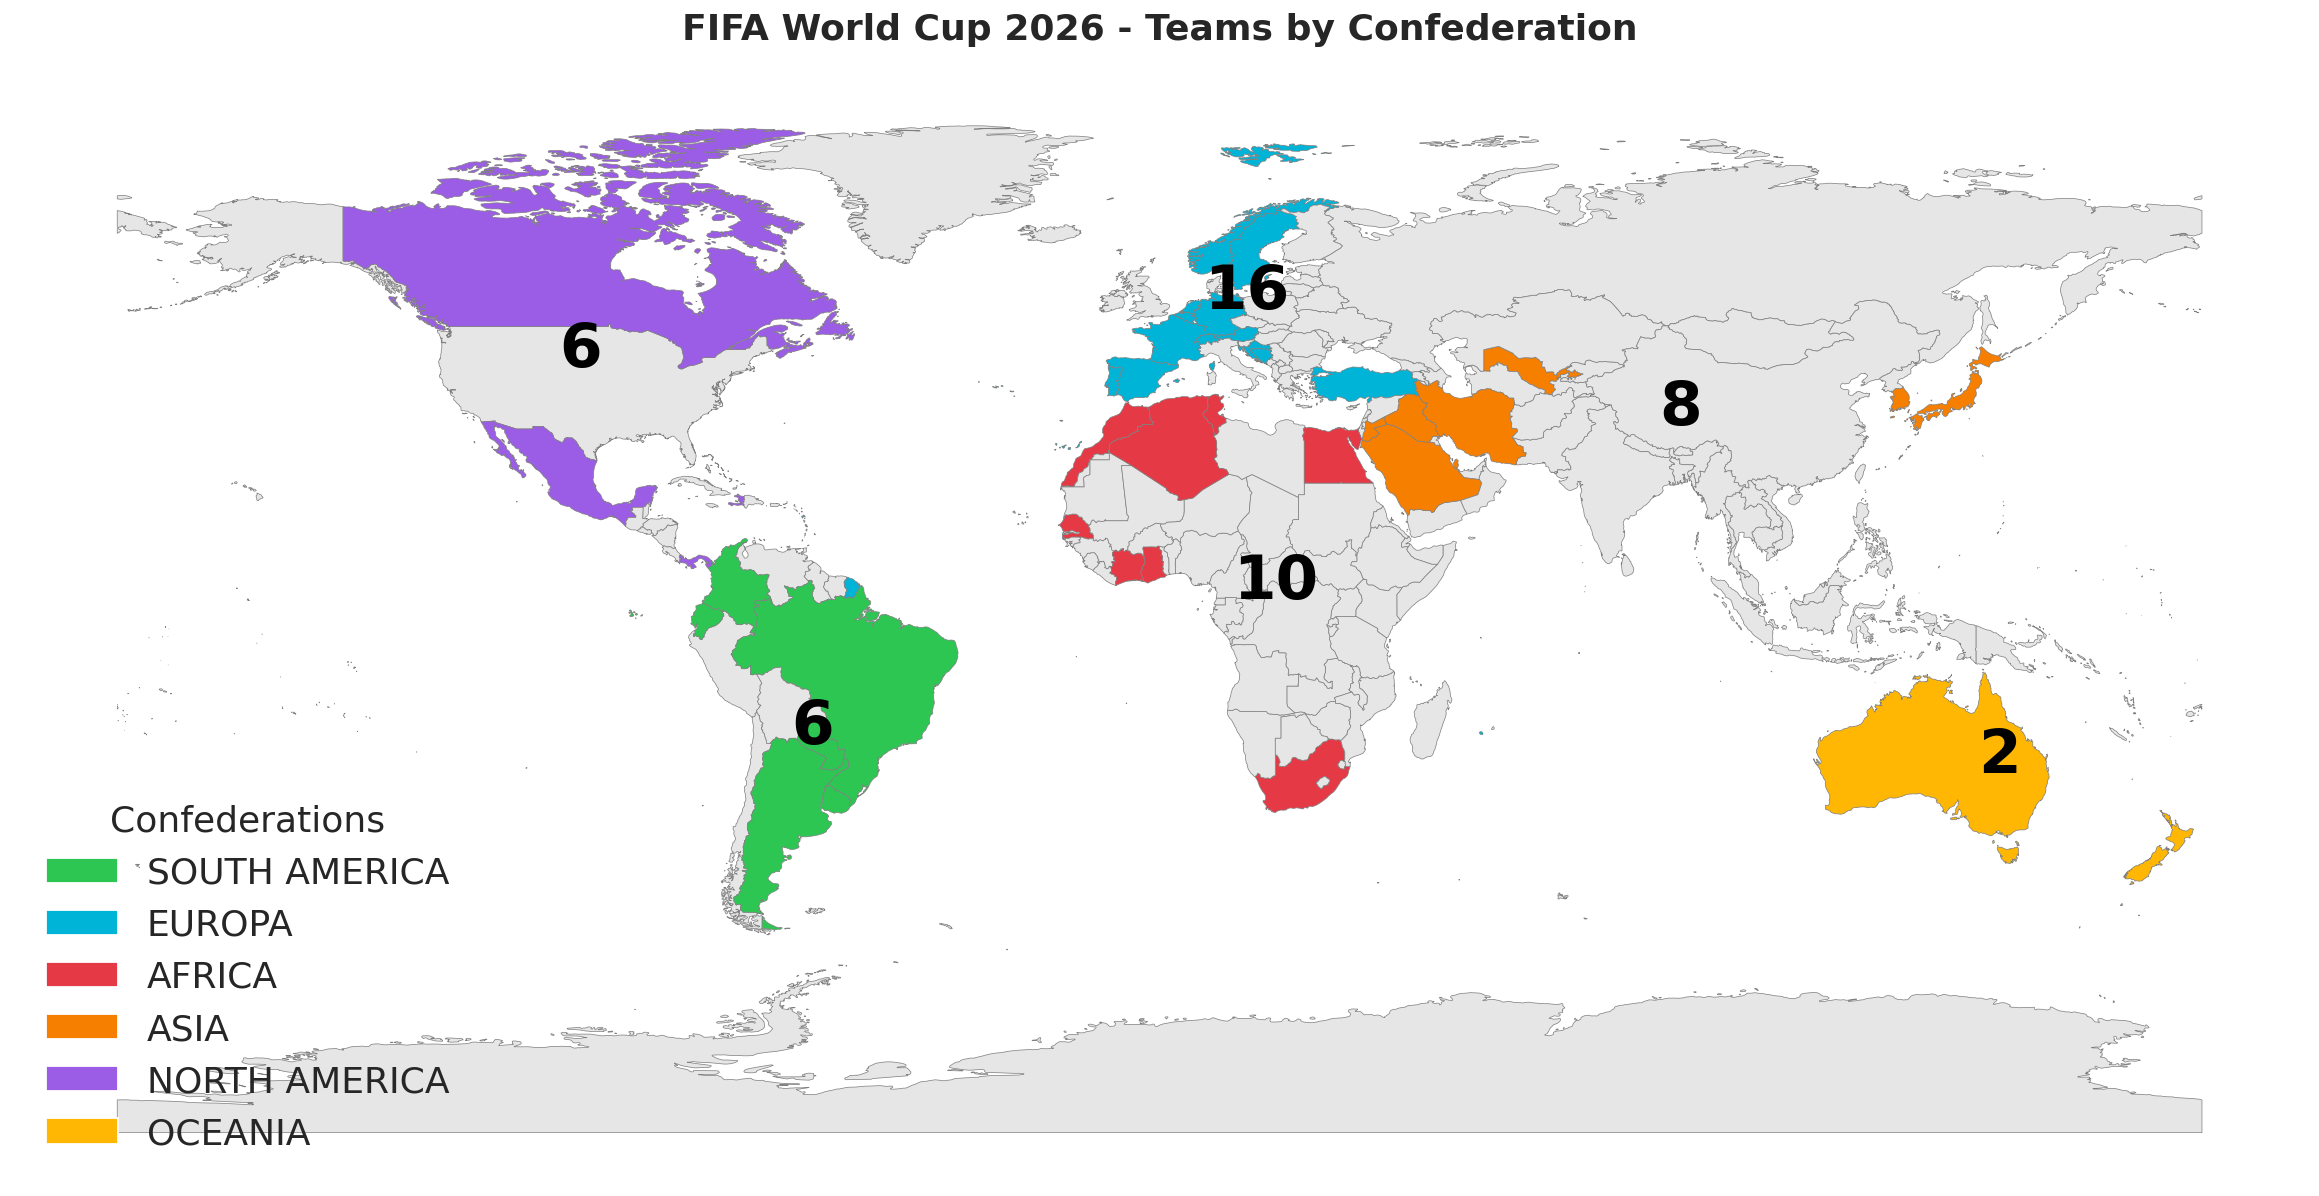

In [197]:
world = gpd.read_file(
    "https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip"
)

# COLORES CONFEDERACIONES
continent_colors = {
    "South America": "#2DC653",   # CONMEBOL
    "Europe": "#00B4D8",          # UEFA
    "Africa": "#E63946",          # CAF
    "Asia": "#F77F00",            # AFC
    "North America": "#9B5DE5",   # CONCACAF
    "Oceania": "#FFB703"          # OFC
}

# COLOREAR PAÍSES
world["color"] = "#E6E6E6"

for _, row in test.iterrows():

    world.loc[
        world["ADMIN"] == row["team"],
        "color"
    ] = continent_colors[row["continent"]]

# FIGURA
fig, ax = plt.subplots(
    figsize=(18, 10),
    dpi=130
)

world.plot(
    color=world["color"],
    edgecolor="grey",
    linewidth=0.4,
    ax=ax
)


# NÚMERO DE EQUIPOS
counts_continent = test["continent"].value_counts()

positions = {
    "North America": (-100, 45),
    "South America": (-60, -20),
    "Europe": (15, 55),
    "Africa": (20, 5),
    "Asia": (90, 35),
    "Oceania": (145, -25)
}

for continent, count in counts_continent.items():

    if continent in positions:

        x, y = positions[continent]

        ax.text(
            x,
            y,
            str(count),
            fontsize=34,
            fontweight="bold",
            ha="center",
            va="center",
            color="black"
        )

# LEYENDA
legend_elements = [
    Patch(facecolor="#2DC653", label="SOUTH AMERICA"),
    Patch(facecolor="#00B4D8", label="EUROPA"),
    Patch(facecolor="#E63946", label="AFRICA"),
    Patch(facecolor="#F77F00", label="ASIA"),
    Patch(facecolor="#9B5DE5", label="NORTH AMERICA"),
    Patch(facecolor="#FFB703", label="OCEANIA")
]

ax.legend(
    handles=legend_elements,
    title="Confederations",
    loc="lower left",
    fontsize=20,
    title_fontsize=20,
    frameon=False
)

# TÍTULO
ax.set_title(
    "FIFA World Cup 2026 - Teams by Confederation",
    fontsize=20,
    fontweight="bold",
    pad=20
)

ax.axis("off")

plt.tight_layout()
plt.show()

##**¿Cómo ha sido el rendimiento reciente de las selecciones clasificadas para la Copa Mundial de la FIFA 2026?**
<small>


> Esta tabla clasifica a las **20 selecciones** clasificadas para la Copa Mundial de la FIFA 2026 según su **porcentaje de victorias en los últimos cuatro años**. La longitud de cada barra representa su porcentaje de victorias, mientras que el color indica su diferencia de goles, ofreciendo una visión general de las selecciones con mejor desempeño que participan en el torneo.

In [172]:
top20 = test.nlargest(20, 'win_rate').sort_values('win_rate', ascending=True)

fig = px.bar(
    top20, x='win_rate', y='team', orientation='h',
    color='goal_diff', text='win_rate',
    title='FIFA World Cup 2026 — Top 15 Teams by Win Rate',
    labels={'win_rate': 'Win Rate (last 4 years)', 'team': '', 'goal_diff': 'Goal Difference'},
    color_continuous_scale='RdYlGn'
)
fig.update_traces(texttemplate='%{text:.1%}', textposition='outside')
fig.update_layout(
    plot_bgcolor='white',
    xaxis=dict(tickformat='.0%', gridcolor='#f0f0f0'),
    yaxis=dict(gridcolor='#f0f0f0'),
    title_font_size=16,
    margin=dict(t=60, b=40, r=100),
    coloraxis_colorbar=dict(title='Goal Diff')
)
fig.show(renderer="colab")

##**Influye el valor de mercado de una plantilla en el rendimiento de una selección durante la Copa Mundial?**
<small>

> Comparamos el valor de mercado de las plantillas con el rendimiento real de los equipos en cada torneo.

In [173]:
fig = px.box(
    train, x='performance', y='market_value_M',
    color='performance',
    category_orders={'performance': order},
    color_discrete_map=colors,
    title='Squad Market Value vs Tournament Performance (2002–2022)',
    labels={'performance': '', 'market_value_M': 'Squad Market Value (€ Millions)'},
    points='all'
)
fig.update_layout(plot_bgcolor='white', yaxis=dict(gridcolor='#f0f0f0'),
                  showlegend=False, title_font_size=16, margin=dict(t=60, b=40))
fig.show(renderer="colab")


###**Que dice el digrama de cajas de la relacion entre valor plantilla y rendioomiento?**
El diagrama de caja muestra la distribución de los valores de las plantillas dentro de cada grupo de rendimiento. La línea central representa la mediana: la mitad de los equipos se sitúan por encima y la otra mitad por debajo.

* Los ganadores y finalistas solían tener plantillas valoradas en más de 800
millones de euros

* Algunos cuartofinalistas invirtieron más de 1600 millones de euros y aun así no lograron llegar a las semifinales.

* Por otro lado, algunos semifinalistas invirtieron menos de 250 millones de euros y superaron a plantillas con un valor cinco veces mayor.

Se necesita un nivel mínimo de inversión para competir, pero a partir de cierto umbral, el dinero deja de ser garantía de éxito. Marruecos (435 millones de euros) y Japón (223 millones de euros) se encuentran entre los cinco primeros por porcentaje de victorias.

##**¿Existe una relación entre la posición en el Ranking FIFA y las posibilidades de ganar la Copa Mundial?**
<small>

> Se supone que el ranking FIFA mide la calidad de los equipos, pero ¿predice realmente quién llega lejos? Comparamos el ranking previo al torneo con el rendimiento real entre 2002 y 2022. Un número menor indica un mejor ranking.

In [174]:
fig = px.box(
    train, x='performance', y='fifa_rank_pre_tournament',
    color='performance',
    category_orders={'performance': order},
    color_discrete_map=colors,
    title='FIFA Ranking vs Tournament Performance (2002–2022)',
    labels={'performance': '', 'fifa_rank_pre_tournament': 'FIFA Ranking (lower = better)'},
    points='all'
)
fig.update_yaxes(autorange='reversed')
fig.update_layout(plot_bgcolor='white', yaxis=dict(gridcolor='#f0f0f0'),
                  showlegend=False, title_font_size=16, margin=dict(t=60, b=40))
fig.show(renderer="colab")



###**Lo que revela el ranking FIFA**

* Todos los campeones del mundo entre 2002 y 2022 se ubicaron entre los 10 primeros antes del torneo. Sin excepción.

* Los finalistas también se ubicaron consistentemente entre los 10 primeros.

Los cuartofinalistas muestran la mayor variación: algunos se ubicaron en el puesto 5, otros en el 50. Aquí es donde ocurren las sorpresas más frecuentes.
Algunos equipos de alto nivel (entre los 5 primeros) fueron eliminados en la fase de grupos; el ranking por sí solo no es suficiente.
¿Qué significa esto para 2026?


<br>

| Selección | Ranking FIFA | Porcentaje de victorias | Observación |
|-----------|:------------:|:-----------------------:|-------------|
| 🇫🇷 Francia | 1 | **65,8 %** | ⚠️ Ocupa el primer lugar del ranking, pero su rendimiento reciente es inferior al esperado. |
| 🇪🇸 España | 2 | **74,4 %** | ✅ Combina un ranking de élite con un rendimiento sobresaliente. |
| 🇦🇷 Argentina | 3 | **81,1 %** | ✅ Presenta el mejor porcentaje de victorias entre las selecciones clasificadas. |
| 🏴 Inglaterra | 4 | **66,7 %** | ✅ Mantiene un rendimiento sólido y acorde con su posición en el ranking. |
| 🇧🇷 Brasil | 6 | **42,9 %** | ⚠️ Registra el rendimiento más bajo entre las selecciones mejor clasificadas. |
| 🇲🇦 Marruecos | 8 | **77,1 %** | ✅ Supera ampliamente las expectativas de acuerdo con su posición en el ranking FIFA. |

##**¿La experiencia en Copas Mundiales aumenta las probabilidades de obtener mejores resultados en el torneo?**
<small>

> Comparamos el número de participaciones anteriores con la etapa en la que llegaron, usando el tamaño de los puntos para mostrar el valor de mercado de la plantilla.


In [176]:
train['market_value_M'] = train['market_value_M'].fillna(train['market_value_M'].median())

fig = px.scatter(
    train,
    x='world_cup_participations_before', y='fifa_rank_pre_tournament',
    color='performance', size='market_value_M',
    hover_name='team', hover_data=['version', 'win_rate'],
    category_orders={'performance': order},
    color_discrete_map=colors,
    title='World Cup Experience vs FIFA Ranking — Colored by Performance (2002–2022)',
    labels={
        'world_cup_participations_before': 'Previous World Cup Appearances',
        'fifa_rank_pre_tournament': 'FIFA Ranking (lower = better)',
        'performance': 'Performance', 'market_value_M': 'Squad Value (€M)'
    }
)
fig.update_yaxes(autorange='reversed')
fig.update_layout(plot_bgcolor='white', yaxis=dict(gridcolor='#f0f0f0'),
                  xaxis=dict(gridcolor='#f0f0f0'), title_font_size=16, margin=dict(t=60, b=40))
fig.show(renderer="colab")

###**Que nos dice el grafico sobre la experiencia?**

* **Los ganadores** (puntos amarillos) se agrupan en la parte superior independientemente de la experiencia: el ranking de élite importa más que la cantidad de participaciones en una Copa del Mundo.

* La experiencia por sí sola no basta: **Brasil y Alemania** aparecen como puntos rojos (**eliminación temprana**) en algunas ediciones a pesar de haber participado entre 15 y 20 veces.

* **Las selecciones debutantes de 2026** pueden sorprender(**Cabo Verde, Curazao, Jordania, Uzbekistán)**: hay puntos verdes y morados cerca de cero participaciones, lo que demuestra que los debutantes pueden llegar a cuartos de final con el rendimiento adecuado y la historia indica que tendrán dificultades, **pero el ranking y el rendimiento serán el factor decisivo**, no la experiencia.

##**¿Qué tan significativa es la ventaja de ser el país anfitrión en la Copa Mundial de la FIFA?**

In [179]:
host_performance = train.groupby('is_host')['performance'].value_counts(normalize=True).mul(100).round(1).reset_index()
host_performance.columns = ['is_host', 'performance', 'percentage']
host_performance['host_label'] = host_performance['is_host'].map({1: 'Host Nation', 0: 'Non-Host Nation'})

fig = px.bar(
    host_performance, x='performance', y='percentage',
    color='host_label', barmode='group',
    category_orders={'performance': order},
    title='Host vs Non-Host Performance Distribution (2002–2022)',
    labels={'performance': '', 'percentage': 'Percentage of Teams (%)', 'host_label': ''},
    color_discrete_sequence=['#FFB703', '#00B4D8']
)
fig.update_layout(plot_bgcolor='white', yaxis=dict(gridcolor='#f0f0f0'),
                  title_font_size=16, margin=dict(t=60, b=40),
                  legend=dict(orientation='h', yanchor='bottom', y=1.02))
fig.update_traces(texttemplate='%{y}%', textposition='outside')
fig.show(renderer="colab")

| País anfitrión | Mundial | Resultado alcanzado |
|----------------|:-------:|---------------------|
| 🇯🇵 Japón | 2002 | Fase de grupos / Octavos de final |
| 🇰🇷 Corea del Sur | 2002 | Semifinalista |
| 🇩🇪 Alemania | 2006 | Semifinalista |
| 🇿🇦 Sudáfrica | 2010 | Fase de grupos / Octavos de final |
| 🇧🇷 Brasil | 2014 | Semifinalista |
| 🇷🇺 Rusia | 2018 | Cuartofinalista |
| 🇶🇦 Catar | 2022 | Fase de grupos / Octavos de final |

##**¿Existe un rango óptimo de edad promedio en las plantillas de las selecciones campeonas del mundo??**

* Demasiado jóvenes = falta de experiencia.
* Demasiado mayores = declive físico.

In [181]:
age_performance = train.groupby('performance')['squad_avg_age'].agg(['mean','min','max']).round(2)
age_performance.columns = ['Average Age', 'Youngest Squad', 'Oldest Squad']
print("=== SQUAD AGE BY PERFORMANCE ===")
print(age_performance.reindex(order).to_string())

fig = px.box(
    train, x='performance', y='squad_avg_age',
    color='performance',
    category_orders={'performance': order},
    color_discrete_map=colors, points='all',
    title='Squad Average Age vs Tournament Performance (2002–2022)',
    labels={'performance': '', 'squad_avg_age': 'Squad Average Age'}
)
fig.add_hrect(y0=26.5, y1=27.5, fillcolor='gold', opacity=0.15, line_width=0,
              annotation_text='Winner Sweet Spot (26.5–27.5)',
              annotation_position='top right', annotation_font_color='goldenrod')
fig.update_layout(plot_bgcolor='white', yaxis=dict(gridcolor='#f0f0f0'),
                  showlegend=False, title_font_size=16, margin=dict(t=60, b=40))
fig.show(renderer="colab")

=== SQUAD AGE BY PERFORMANCE ===
                   Average Age  Youngest Squad  Oldest Squad
performance                                                 
Winner                   26.74           26.03         27.80
Finalist                 27.50           26.50         28.92
Semi_finalist            27.10           26.05         28.36
Quarter_finalist         27.31           25.10         28.84
Group Stage / R16        27.26           23.92         29.78


###**Equipos con edad ideal para ser CAMPEONES🏆:**

In [184]:
sweet_spot = test[(test['squad_avg_age'] >= 26.03) & (test['squad_avg_age'] <= 27.80)]    [['team','squad_avg_age','fifa_rank_pre_tournament','win_rate']]    .sort_values('fifa_rank_pre_tournament')

print(f"=== TEAMS IN THE WINNER AGE SWEET SPOT ({len(sweet_spot)} of 48) ===")
print(sweet_spot.to_string(index=False))

=== TEAMS IN THE WINNER AGE SWEET SPOT (27 of 48) ===
                  team  squad_avg_age  fifa_rank_pre_tournament  win_rate
                France           26.7                         1     0.658
                 Spain           27.2                         2     0.744
               England           26.8                         4     0.667
              Portugal           27.1                         5     0.684
                Brazil           27.8                         6     0.429
           Netherlands           26.6                         7     0.553
               Morocco           27.4                         8     0.771
               Belgium           27.1                         9     0.528
               Germany           26.6                        10     0.553
               Senegal           27.4                        14     0.721
               Uruguay           26.6                        17     0.410
                 Japan           26.4                     

#**¿Qué selección presenta el perfil más sólido para ganar la Copa Mundial de la FIFA 2026?**

##🏆 Composite Team Score (CTS)

 **Objetivo:** Integrar las principales variables de rendimiento en una **puntuación compuesta** para clasificar las 48 selecciones clasificadas al Mundial FIFA 2026.


<br>

## ⚖️ Sistema de puntuacion

| Indicador | Peso |
|:-------------------------------|:---:|
| 🟢 Win Rate (Porcentaje de victorias) | **25 %** |
| 🌍 FIFA Ranking (Clasificación FIFA) | **25 %** |
| ⚽ Goal Difference (Diferencia de goles) | **15 %** |
| 💰 Market Value (Valor de mercado) | **10 %** |
| 🏆 World Cup Titles (Títulos mundiales) | **10 %** |
| 👥 Average Squad Age (Edad promedio de la plantilla) | **10 %** |
| 🎖️ World Cup Appearances (Participaciones en Mundiales) | **5 %** |

<br>

### 📌 Interpretación

La **Composite Team Score (CTS)** asigna una puntuación a cada selección mediante una combinación ponderada de indicadores deportivos, económicos e históricos. Este índice busca reflejar el potencial competitivo de cada equipo antes del Mundial FIFA 2026, equilibrando el rendimiento reciente con la experiencia y el historial en la competición.

In [185]:
from sklearn.preprocessing import MinMaxScaler

scoring_cols = ['win_rate','goal_diff','market_value_M',
                'fifa_points_pre_tournament','world_cup_titles_before','world_cup_participations_before']

pred_df = test[['team','continent','squad_avg_age'] + scoring_cols].copy()
pred_df['rank_score'] = 100 - test['fifa_rank_pre_tournament']
pred_df['age_score']  = 1 - abs(pred_df['squad_avg_age'] - 27.0) / 5

scale_cols = scoring_cols + ['rank_score','age_score']
scaler = MinMaxScaler()
pred_df[scale_cols] = scaler.fit_transform(pred_df[scale_cols])

pred_df['composite_score'] = (
    pred_df['win_rate']                        * 0.25 +
    pred_df['goal_diff']                       * 0.15 +
    pred_df['rank_score']                      * 0.25 +
    pred_df['market_value_M']                  * 0.10 +
    pred_df['world_cup_titles_before']         * 0.10 +
    pred_df['age_score']                       * 0.10 +
    pred_df['world_cup_participations_before'] * 0.05
).round(4)

final_rankings = pred_df[['team','composite_score','continent']]    .sort_values('composite_score', ascending=False)    .reset_index(drop=True)
final_rankings.index += 1

print("=== DATA-DRIVEN 2026 WORLD CUP POWER RANKINGS ===")
print(final_rankings.head(20).to_string())

=== DATA-DRIVEN 2026 WORLD CUP POWER RANKINGS ===
           team  composite_score      continent
1         Spain           0.8335         Europe
2     Argentina           0.8247  South America
3        France           0.7936         Europe
4       England           0.7829         Europe
5       Morocco           0.7372         Africa
6      Portugal           0.7305         Europe
7       Germany           0.6960         Europe
8         Japan           0.6683           Asia
9       Senegal           0.6625         Africa
10       Brazil           0.6435  South America
11  Netherlands           0.6297         Europe
12      Belgium           0.5983         Europe
13      Algeria           0.5878         Africa
14      Austria           0.5417         Europe
15  Ivory Coast           0.5319         Africa
16    Australia           0.5107        Oceania
17       Turkey           0.5103         Europe
18       Norway           0.5097         Europe
19      Uruguay           0.5080  Sout

###**Ranking de los 10 mejores**

In [195]:
continent_colors = {
    'Europe':'#00B4D8','South America':'#FFB703','Africa':'#2DC653',
    'Asia':'#E63946','North America':'#9B5DE5','Oceania':'#F77F00'
}

top16 = final_rankings.head(10).sort_values('composite_score', ascending=False)

fig = px.bar(
    top16, x='team', y='composite_score',
    color='continent', text='composite_score',
    title='FIFA World Cup 2026 — Data Driven Power Rankings (Top 10)',
    labels={'composite_score':'Composite Score (higher = stronger)','team':'','continent':'Continent'},
    color_discrete_map=continent_colors
)
fig.update_traces(texttemplate='%{text:.3f}', textposition='outside')
fig.update_layout(
    plot_bgcolor='white',
    xaxis=dict(gridcolor='#f0f0f0', tickangle=-45),
    yaxis=dict(gridcolor='#f0f0f0', range=[0, 1.0]),
    title_font_size=16, margin=dict(t=60, b=120, r=40),
    legend=dict(orientation='h', yanchor='bottom', y=-0.45)
)
for team in ['Spain','Argentina','France','England']:
    score = final_rankings[final_rankings['team']==team]['composite_score'].values[0]
    fig.add_annotation(x=team, y=score+0.1, text='Top 4',
                       showarrow=False, font=dict(size=15, color='goldenrod'))
fig.show(renderer="colab")

###**Predicción del Mundial de 2026 basada en datos**

# 🏆 Predicción del Modelo – FIFA World Cup 2026

| Predicción | Selección | Composite Score |
|:----------:|-----------|:---------------:|
| 🥇 **Campeón** | 🇪🇸 **España** | **0.834** |
| 🥈 **Subcampeón** | 🇦🇷 **Argentina** | **0.825** |
| 🥉 **Semifinalista** | 🇫🇷 **Francia** | **0.794** |
| 🏅 **Semifinalista** | 🏴 **Inglaterra** | **0.783** |

<br>

### 🥇 Campeón — 🇪🇸 España
**Composite Score:** **0.834**

**Justificación:**  
Ranking FIFA de élite, excelente rendimiento reciente, edad promedio óptima y una sólida trayectoria histórica.

---
<br>

### 🥈 Subcampeón — 🇦🇷 Argentina
**Composite Score:** **0.825**

**Justificación:**  
Presenta el mayor porcentaje de victorias (**81,1 %**), aunque su edad promedio está ligeramente por encima del rango óptimo.

---

<br>

### 🥉 Semifinalista — 🇫🇷 Francia
**Composite Score:** **0.794**

**Justificación:**  
Ocupa el primer lugar del ranking FIFA, pero su rendimiento reciente (**65,8 %**) es inferior al esperado para su posición.

---
<br>

### 🏅 Semifinalista — 🏴 Inglaterra
**Composite Score:** **0.783**

**Justificación:**  
Mantiene un rendimiento consistente en todos los indicadores y una edad promedio dentro del rango óptimo.


<BR>

###**Equipo decepcion 👎:**
**Brasil (0.643**) — pentacampeón, solo 10.° en la clasificación general. Su porcentaje de victorias del 42,9 % es la cifra más alarmante para cualquier equipo de élite en este conjunto de datos.

<br>

> ⚠️ Descargo de responsabilidad: Esta predicción se basa exclusivamente en datos previos al torneo. El fútbol es maravillosamente impredecible: lesiones, empates, árbitros, penaltis y suerte influyen de maneras que ningún conjunto de datos puede reflejar. Esto es lo que dicen los números. Lo que sucede en el campo es otra historia.